# Supply Chain Delivery Delay & Risk Analysis — Exploratory Data Analysis

This notebook analyzes patterns associated with late delivery risk in the DataCo Supply Chain dataset. The goal is to identify business areas where delivery delays appear more frequent and to generate insights that can inform later predictive modeling.

**Target variable:** `late_delivery_risk`

**Notebook purpose:** Business-focused EDA, not model training.

**Important note:** Some fields may be useful for understanding delivery outcomes but may later cause leakage in predictive modeling.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
from folium.plugins import HeatMap

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [ ]:
df=pd.read_parquet("../data/cleaned/cleaned_supply_chain_data.parquet")
df.head()

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_fname,customer_id,customer_lname,customer_segment,customer_state,customer_street,customer_zipcode,department_id,department_name,latitude,longitude,market,order_city,order_country,order_customer_id,order_date_dateorders,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,product_card_id,product_category_id,product_image,product_name,product_price,shipping_date_dateorders,shipping_mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,Cally,20755,Holloway,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,Irene,19492,Luna,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,Gillian,19491,Maldonado,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,Tana,19490,Tate,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,Orli,19489,Hendricks,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,2018-01-15 11:24:00,Standard Class


In [ ]:
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
def delay_rate_summary(df, group_col, target_col="late_delivery_risk", min_orders=100):
    summary = (
        df[[group_col, target_col]]
        .dropna()
        .groupby([group_col, target_col])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=[0, 1], fill_value=0)
        .rename(columns={0: "on_time_orders", 1: "late_orders"})
    )

    summary["total_orders"] = summary["on_time_orders"] + summary["late_orders"]
    summary["late_rate"] = summary["late_orders"] / summary["total_orders"] * 100

    summary = summary[summary["total_orders"] >= min_orders]
    summary = summary.sort_values("late_rate", ascending=False)

    return summary.reset_index()

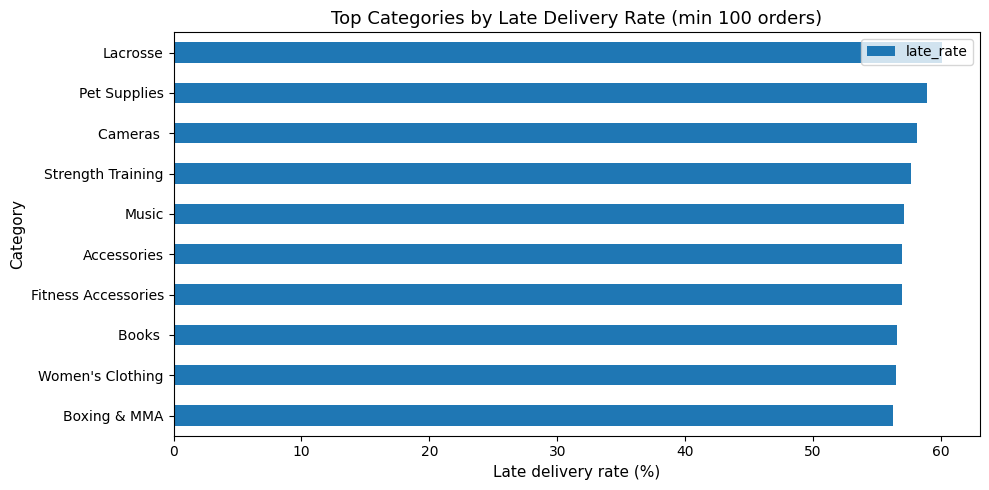

In [ ]:
category_delay = delay_rate_summary(df, "category_name", min_orders=100)

category_delay.head(10).plot(
    kind="barh",
    x="category_name",
    y="late_rate",
    title="Top Categories by Late Delivery Rate (min 100 orders)"
)
plt.xlabel("Late delivery rate (%)")
plt.ylabel("Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

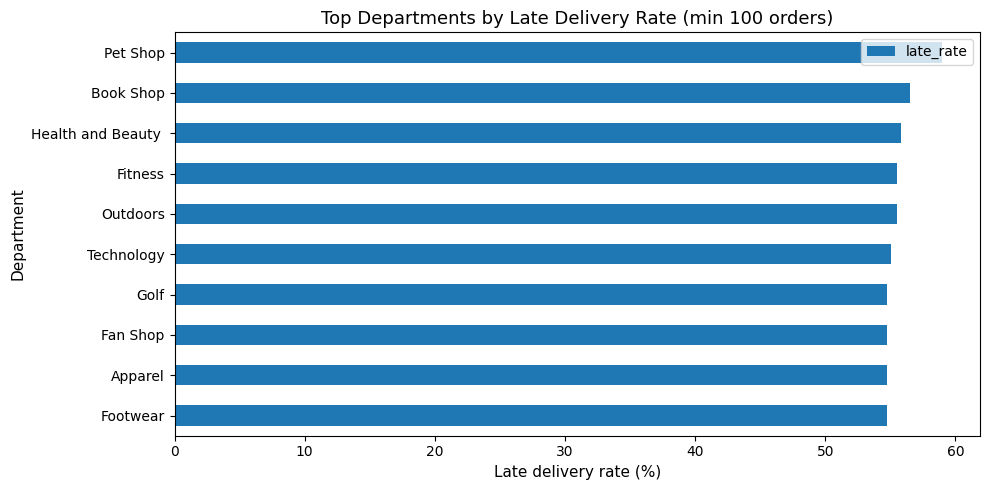

In [ ]:
orders_delayed_by_department=delay_rate_summary(df, "department_name", min_orders=100)
orders_delayed_by_department.head(10).plot(
    kind="barh",
    x="department_name",
    y="late_rate",
    title="Top Departments by Late Delivery Rate (min 100 orders)"
)
plt.xlabel("Late delivery rate (%)")
plt.ylabel("Department")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

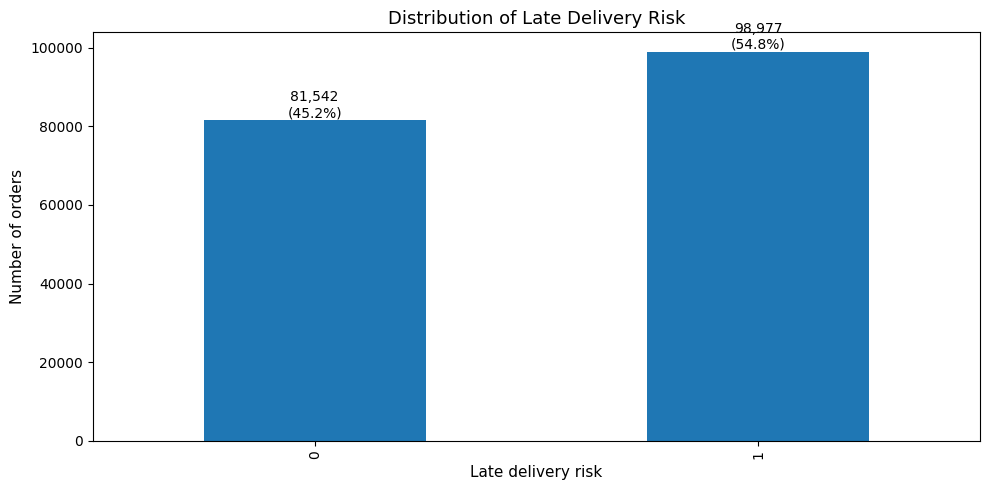

In [ ]:
target_counts = df["late_delivery_risk"].value_counts().sort_index()
target_pct = df["late_delivery_risk"].value_counts(normalize=True).sort_index() * 100

ax = target_counts.plot(kind="bar", title="Distribution of Late Delivery Risk")
plt.xlabel("Late delivery risk")
plt.ylabel("Number of orders")

for i, v in enumerate(target_counts.values):
    plt.text(i, v, f"{v:,}\n({target_pct.iloc[i]:.1f}%)", ha="center", va="bottom")

plt.tight_layout()
plt.show()

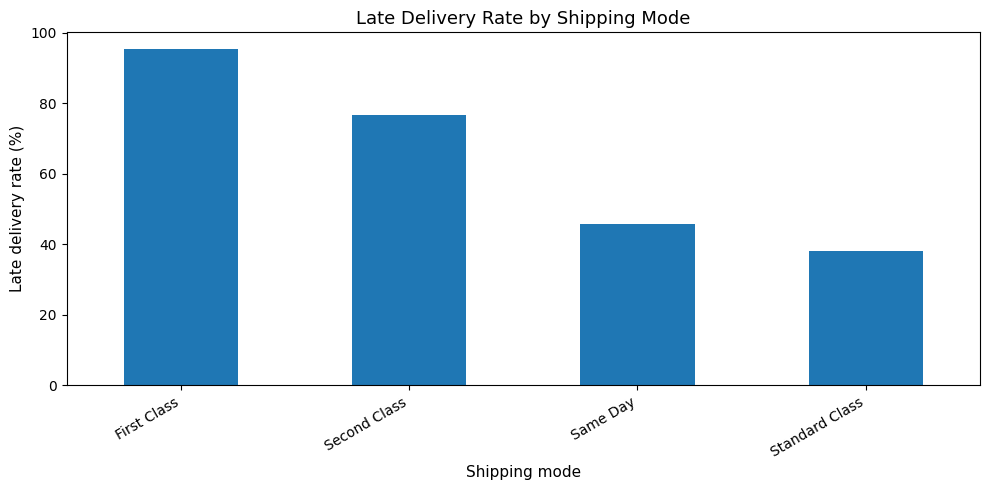

In [ ]:
shipping_delay = (
    df.groupby(["shipping_mode", "late_delivery_risk"])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=[0, 1], fill_value=0)
      .rename(columns={0: "on_time_orders", 1: "late_orders"})
)

shipping_delay["total_orders"] = shipping_delay.sum(axis=1)
shipping_delay["late_rate"] = shipping_delay["late_orders"] / shipping_delay["total_orders"] * 100
shipping_delay = shipping_delay.sort_values("late_rate", ascending=False)

shipping_delay["late_rate"].plot(kind="bar", title="Late Delivery Rate by Shipping Mode")
plt.ylabel("Late delivery rate (%)")
plt.xlabel("Shipping mode")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

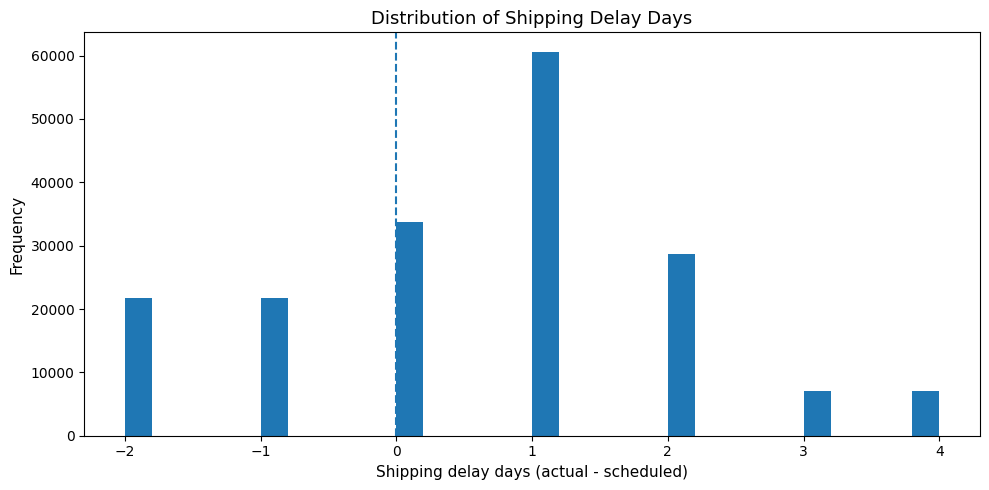

In [ ]:
df["shipping_delay_days"] = df["days_for_shipping_real"] - df["days_for_shipment_scheduled"]

df["shipping_delay_days"].dropna().plot(
    kind="hist",
    bins=30,
    title="Distribution of Shipping Delay Days"
)
plt.axvline(0, linestyle="--")
plt.xlabel("Shipping delay days (actual - scheduled)")
plt.tight_layout()
plt.show()

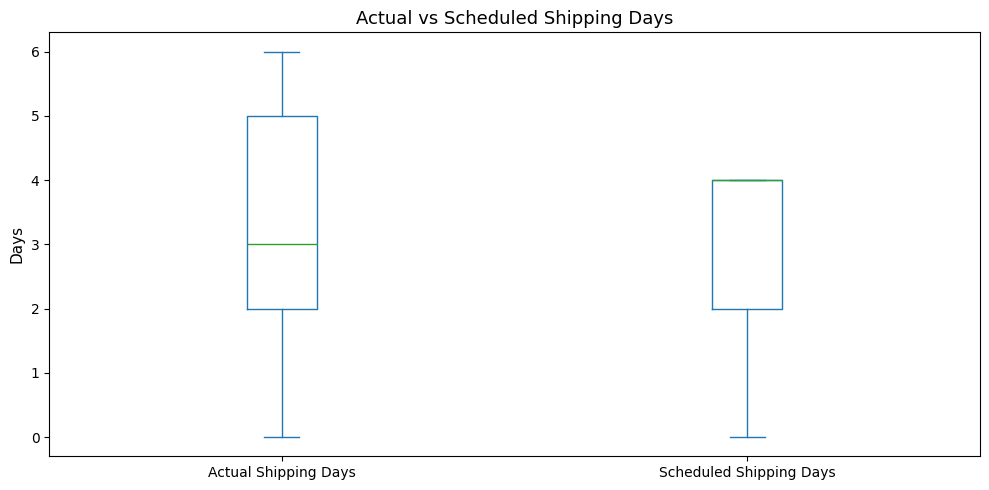

In [ ]:
shipping_compare = df[["days_for_shipping_real", "days_for_shipment_scheduled"]].copy()
shipping_compare.columns = ["Actual Shipping Days", "Scheduled Shipping Days"]

shipping_compare.plot(kind="box", title="Actual vs Scheduled Shipping Days")
plt.ylabel("Days")
plt.tight_layout()
plt.show()

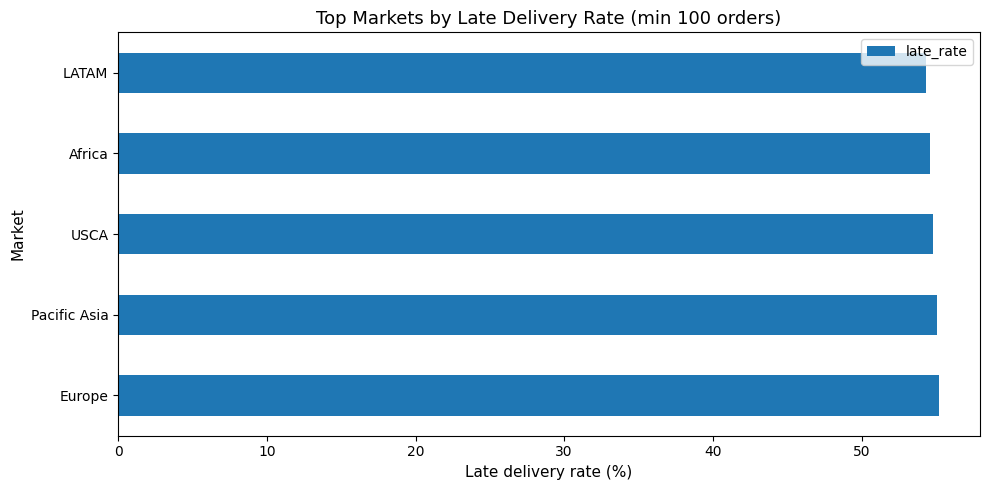

In [ ]:
market_delay_rate=delay_rate_summary(df, "market", min_orders=100)
market_delay_rate.head(10).plot(
    kind="barh",
    x="market",
    y="late_rate",
    title="Top Markets by Late Delivery Rate (min 100 orders)"
)
plt.xlabel("Late delivery rate (%)")
plt.ylabel("Market")
plt.tight_layout()
plt.show()

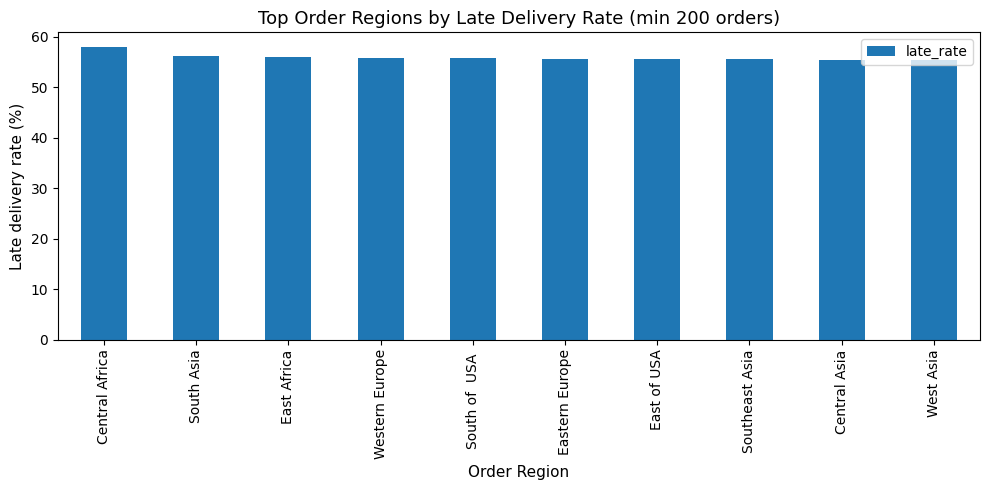

In [ ]:
region_delay = delay_rate_summary(df, "order_region", min_orders=200)
region_delay.head(10).plot(
    kind="bar",
    x="order_region",
    y="late_rate",
    title="Top Order Regions by Late Delivery Rate (min 200 orders)"
)
plt.ylabel("Late delivery rate (%)")
plt.xlabel("Order Region")
plt.tight_layout()
plt.show()

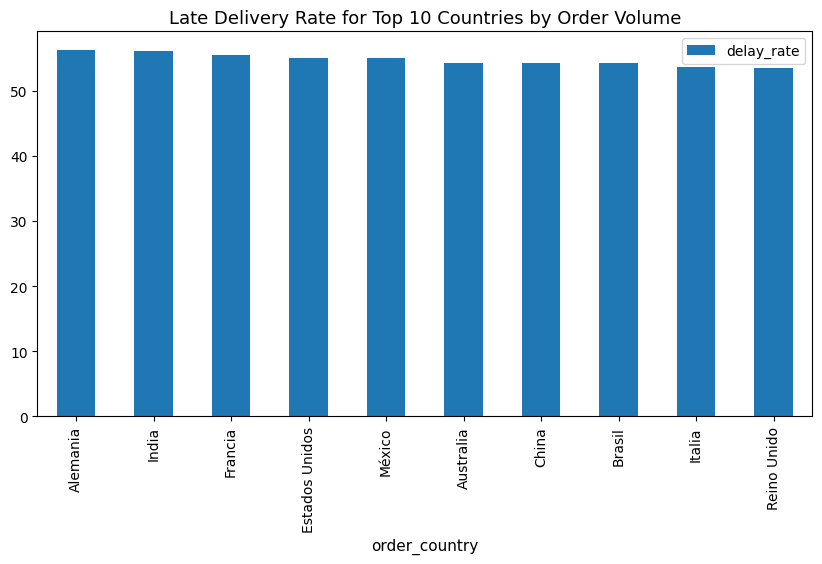

In [ ]:
top_countries=df.groupby(['order_country', 'late_delivery_risk']).size().unstack(fill_value=0).rename(columns={0: 'on_time', 1: 'late'}).reset_index()
top_countries['total'] = top_countries['on_time'] + top_countries['late']
top_countries=top_countries.sort_values(by='total', ascending=False).head(10)
top_countries['delay_rate'] = top_countries['late'] / top_countries['total'] * 100
top_countries.sort_values(by='delay_rate', ascending=False).plot(kind='bar', x='order_country', y='delay_rate', title='Late Delivery Risk by Country')
plt.title("Late Delivery Rate for Top 10 Countries by Order Volume")
plt.show()

In [ ]:
map_df = df[["latitude", "longitude"]].dropna().copy()
map_df.head()

,latitude,longitude
0,18.251453,-66.037056
1,18.279451,-66.037064
2,37.292233,-121.881279
3,34.125946,-118.291016
4,18.253769,-66.037048


In [ ]:
delay_df = df[df["late_delivery_risk"] == 1][["latitude", "longitude"]].dropna()

m_delay = folium.Map(
    location=[delay_df["latitude"].mean(), delay_df["longitude"].mean()],
    zoom_start=2
)

HeatMap(delay_df.values.tolist()).add_to(m_delay)

m_delay

In [ ]:
m_delay.save("../outputs/figures/delay_heatmap.html")

In [ ]:
sales_summary = df.groupby("late_delivery_risk")["sales"].agg(["mean", "median"])
profit_summary = df.groupby("late_delivery_risk")["order_profit_per_order"].agg(["mean", "median"])

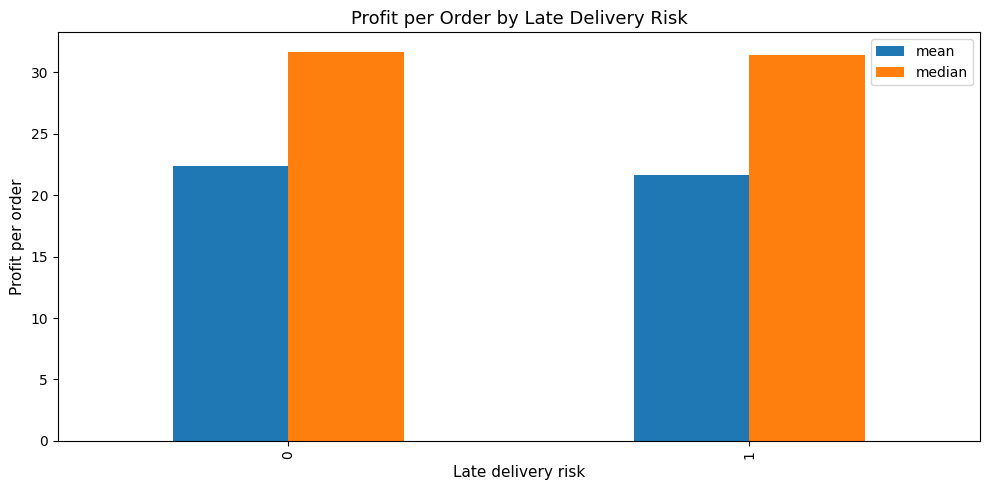

In [ ]:
profit_summary.plot(kind="bar", title="Profit per Order by Late Delivery Risk")
plt.ylabel("Profit per order")
plt.xlabel("Late delivery risk")
plt.tight_layout()
plt.show()

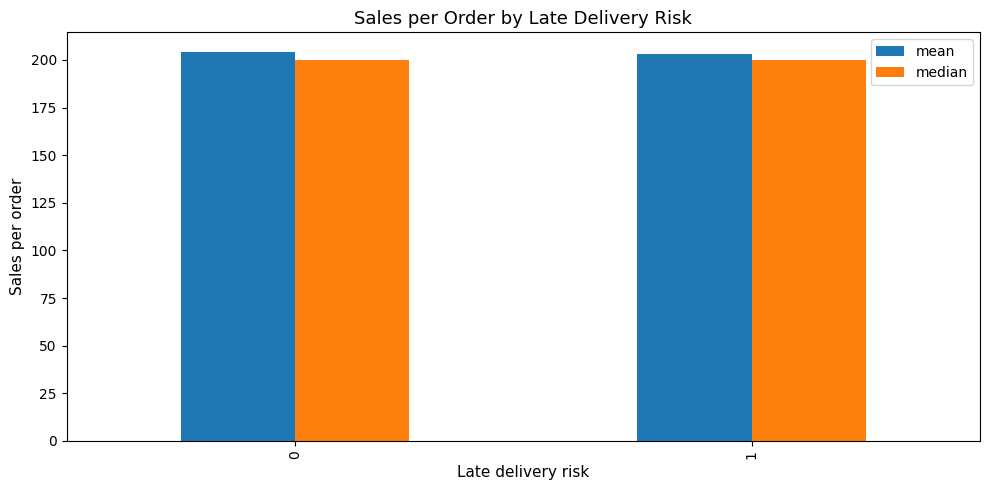

In [ ]:
sales_summary.plot(kind="bar", title="Sales per Order by Late Delivery Risk")
plt.ylabel("Sales per order")
plt.xlabel("Late delivery risk")
plt.tight_layout()
plt.show()

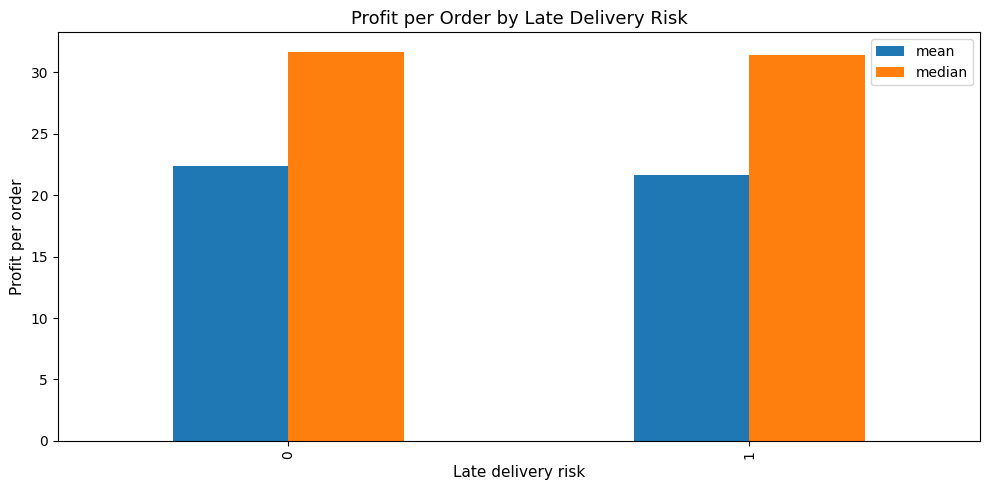

In [ ]:
df.groupby("late_delivery_risk")["order_profit_per_order"].agg(['mean', 'median']).plot(kind="bar", title="Profit per Order by Late Delivery Risk")
plt.ylabel("Profit per order")
plt.xlabel("Late delivery risk")
plt.tight_layout()
plt.show()

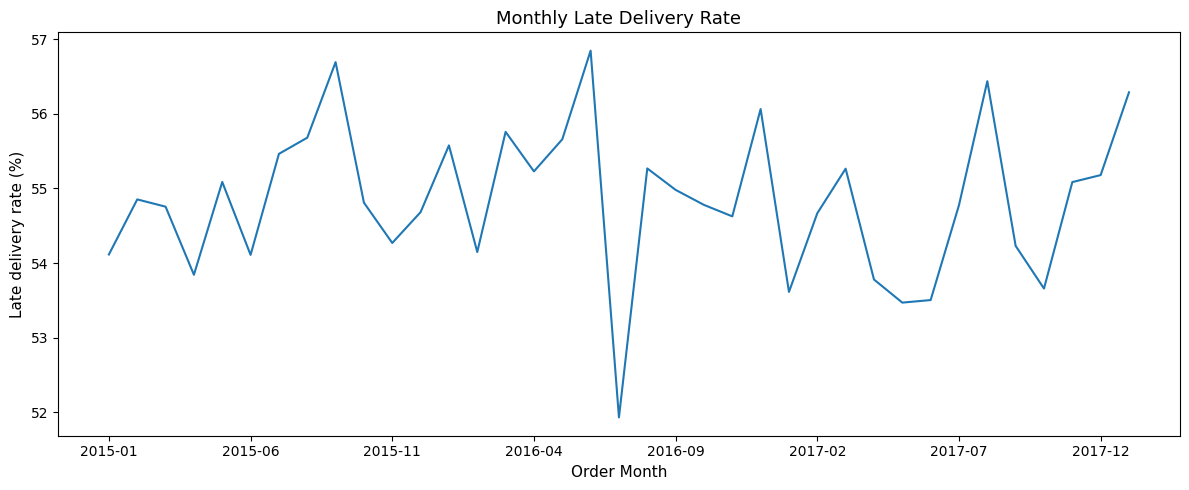

In [ ]:
df["order_month"] = df["order_date_dateorders"].dt.to_period("M").astype(str)
monthly_delay_rate = (
    df.groupby(["order_month", "late_delivery_risk"])
      .size()
      .unstack(fill_value=0)
)

monthly_delay_rate["total_orders"] = monthly_delay_rate.sum(axis=1)
monthly_delay_rate["delay_rate"] = monthly_delay_rate[1] / monthly_delay_rate["total_orders"] * 100

monthly_delay_rate["delay_rate"].plot(figsize=(12,5))
plt.title("Monthly Late Delivery Rate")
plt.xlabel("Order Month")
plt.ylabel("Late delivery rate (%)")
plt.tight_layout()
plt.show()